---
---
## Trabajo Práctico 6 - Test de Hipótesis
---
---

La diabetes se diagnostica en base al nivel de glucosa en sangre. Según la base de datos de indios Pima la glucosa en sangre de personas sanas tiene una media $\mu_0 = 110.6\:mg/dl$ y una desviación estándar $\sigma_0 = 24.8\:mg/dl$. Para personas con diabetes la media es $\mu_1 = 142.3\:mg/dl$ y la desviación estándar $\sigma_1 = 29.6\:mg/dl$. Asumir que la glucosa en sangre para personas sanas y con diabetes sigue una distribución normal. Siguiendo las recomendaciones de la Organización Mundial de la Salud, a una persona se le diagnostica diabetes si su nivel de glucosa en sangre excede $126\:mg/dl$. Graficar las distribuciones de la glucosa en sangre para las hipótesis nula y alternativa. Indicar en la figura el valor crítico de la glucosa en sangre.

  Calcular la sensibilidad (poder) del test de glucosa en sangre, la probabilidad que
un paciente sano sea diagnosticado como diabético (falso positivo) y la
probabilidad que un paciente diabético sea diagnosticado como sano (falso negativo). Si la prevalencia de la diabetes es del $35\%$, calcular
aplicando el teorema de Bayes, la probabilidad que una persona con
un test positivo efectivamente tenga diabetes.

In [ ]:
import numpy as np
from matplotlib import pyplot as plt
from scipy.stats import norm

#### Clasificación

**Hipótesis nula $H_0$**: El paciente tiene diabetes

**Hipótesis alternativa $H_1$**: El paciente no tiene diabetes

- Observable: glucosa en sangre
- Objetivo: clasificar cada paciente como enfermos o sanos.

La glucosa en sangre para personas sanas y enfermas siguen una distribucipon normal.

**Valor crítico de la glucosa en sangre:** $x_c = 126 mg/dl$

In [ ]:
# personas sanas
mu_0 = 110.6
sigma_0 = 24.8

# personas enfermas
mu_1 = 142.3
sigma_1 = 29.6

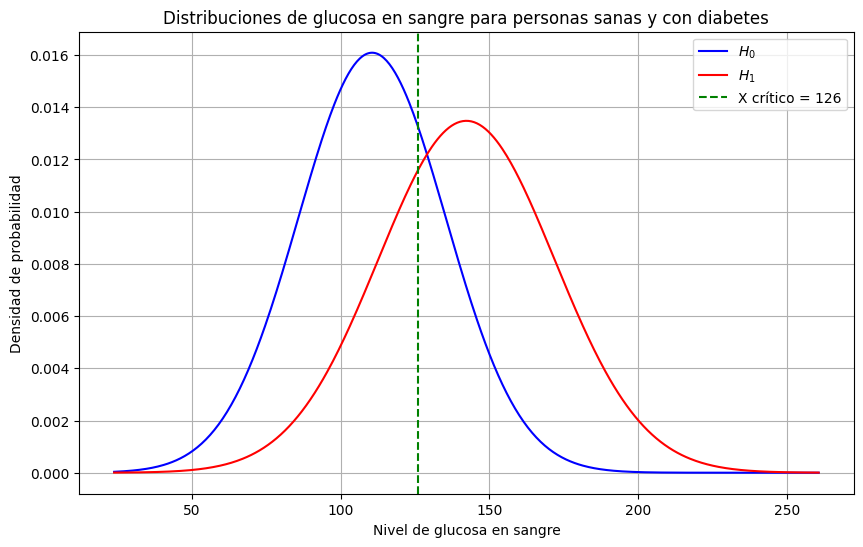

In [ ]:
# Rango de valores de glucosa en sangre para la gráfica
x = np.linspace(mu_1 - 4*sigma_1, mu_1 + 4*sigma_1, 500)

# Distribuciones de probabilidad para personas sanas y enfermas
pdf_H0 = norm.pdf(x, mu_0, sigma_0)
pdf_H1 = norm.pdf(x, mu_1, sigma_1)

# Gráfica
plt.figure(figsize=(10, 6))
plt.plot(x, pdf_H0, label=r"$H_0$", color="blue")
plt.plot(x, pdf_H1, label=r"$H_1$", color="red")

X_critico = 126
plt.axvline(X_critico, color='green', linestyle='--', linewidth=1.5, label=f'X crítico = {X_critico}')
plt.xlabel("Nivel de glucosa en sangre")
plt.ylabel("Densidad de probabilidad")
plt.title("Distribuciones de glucosa en sangre para personas sanas y con diabetes")
plt.legend()
plt.grid(True)
plt.show()

### Sensibilidad y especificidad de un test
La sensibilidad y especifidad de un test están relacionados con los errores de tipo I y II, respectivamente.

- **Error de tipo I ($\alpha$)**: Es la probabilidad de mal clasificar a un paciente sano como enfermo. Es decir, que el valor de glucosa en sangre del paciente sea mayor que el valor crítico y caiga en la zona $H_0$. Sería el área bajo la curva de la distribución $H_0$ a la derecha del valor crítico.
- **Error de tipo II ($\beta$)**: Es la probabilidad de mal clasificar a un paciente enfermo como sano. Esto ocurre cuando el valor de la glucosa en sangre de un paciente da menor que el valor crítico pero cae en la distribución de $H_1$. Sería el área bajo la curva de la distribución $H_1$ a la izquierda del valor crítico.

La sensiblidad (o poder) y especifidad de un test están dadas por:

- $\text{poder} = 1 - \beta$
- $\text{especificidad} = 1 - \alpha$



Es interesante notar que, dado que clasificar a un paciente enfermo como sano es más grave que clasificar a un paciente sano como enfermo, se podría priorizar reducir $\beta$ en comparación con $\alpha$.



In [ ]:
# Calculo de alpha y beta usando la probabilidad acumulada
alpha = 1 - norm.cdf(X_critico, mu_0, sigma_0)
beta = norm.cdf(X_critico, mu_1, sigma_1)

print(f"$\alpha$ (Falso Positivo): {alpha:.2f}")
print(f"$\beta$ (Falso Negativo): {beta:.2f}\n")

# Calculo del poder y especificidad
poder = 1 - beta
especificidad = 1 - alpha

print(f"Poder del test (1 - $\beta$): {poder:.2f}")
print(f"Especificidad (1 - $\alpha$): {especificidad:.2f}")


$lpha$ (Falso Positivo): 0.27
eta$ (Falso Negativo): 0.29

Poder del test (1 - eta$): 0.71
Especificidad (1 - $lpha$): 0.73


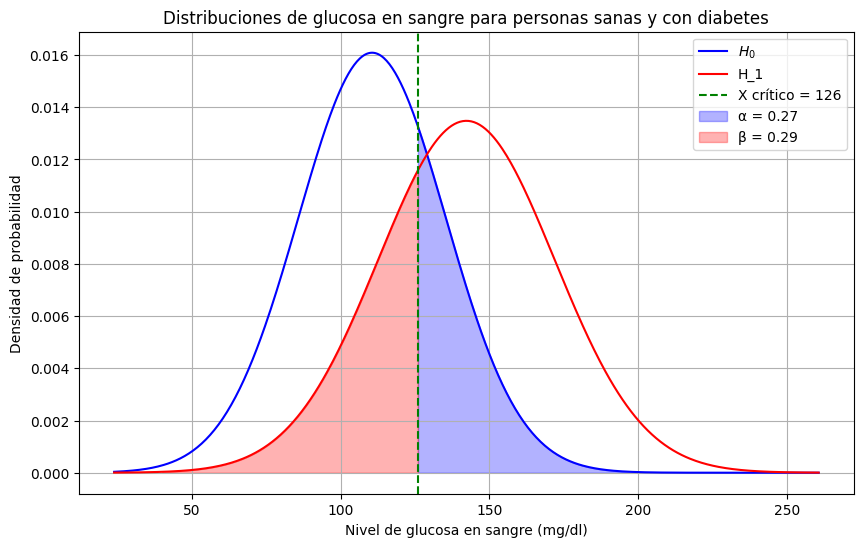

In [ ]:
# Gráfica
plt.figure(figsize=(10, 6))
plt.plot(x, pdf_H0, label=r"$H_0$", color="blue")
plt.plot(x, pdf_H1, label=r"H_1", color="red")

# Línea punteada en X_crítico
plt.axvline(X_critico, color='green', linestyle='--', linewidth=1.5, label=f'X crítico = {X_critico}')

# Sombrear el área de alpha (falsos positivos)
x_alpha = np.linspace(X_critico, 250, 500)
plt.fill_between(x_alpha, norm.pdf(x_alpha, mu_0, sigma_0), color="blue", alpha=0.3, label=f'α = {alpha:.2f}')

# Sombrear el área de beta (falsos negativos)
x_beta = np.linspace(40, X_critico, 500)
plt.fill_between(x_beta, norm.pdf(x_beta, mu_1, sigma_1), color="red", alpha=0.3, label=f'β = {beta:.2f}')

plt.xlabel("Nivel de glucosa en sangre (mg/dl)")
plt.ylabel("Densidad de probabilidad")
plt.title("Distribuciones de glucosa en sangre para personas sanas y con diabetes")
plt.legend()
plt.grid(True)
plt.show()

### Reporte usando la matriz de confusión

$$
\begin{array}{|c|c|c|}
\hline
 & \text{Test Positivo} & \text{Test Negativo} \\
\hline
\text{Diabetes (Verdaderos)} & \text{Verdaderos Positivos (TP)} & \text{Falsos Negativos (FN)} \\
\hline
\text{No Diabetes (Falsos)} & \text{Falsos Positivos (FP)} & \text{Verdaderos Negativos (TN)} \\
\hline
\end{array}
$$


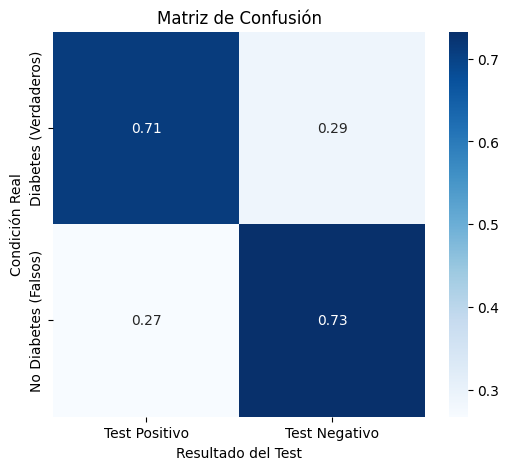

In [ ]:
import seaborn as sns


# matriz de confusión como un arreglo numpy
confusion_matrix = np.array([[poder, beta],
                             [alpha, especificidad]])

# Gráfico
plt.figure(figsize=(6, 5))
sns.heatmap(confusion_matrix, annot=True, cmap="Blues",
            xticklabels=["Test Positivo", "Test Negativo"],
            yticklabels=["Diabetes (Verdaderos)", "No Diabetes (Falsos)"])

plt.title("Matriz de Confusión")
plt.xlabel("Resultado del Test")
plt.ylabel("Condición Real")
plt.show()

### Probabilidad que una persona con un test positivo efectivamente tenga diabetes.

Esta probabilidad considera todos los resultados positivos, tanto de personas con diabetes como de personas sanas (falsos positivos), ponderando cada caso por su probabilidad en la población general.


**Teorema de Bayes:** $P(\text{diabetes | test positivo}) = \frac{P(\text{test positivo | diabetes}) P(\text{diabetes})}{P(\text{positivo})}$

- Probabilidad de obtener un resultado positivo en el test:

$P(\text{positivo}) = P(\text{test positivo | diabetes}) \cdot P(\text{diabetes}) + P(\text{test positivo | no diabetes}) \cdot P(\text{no diabetes})$

- Probabilidad de que una persona tenga diabetes: $P(\text{diabetes}) = 35\%$
- Probabilidad de que una persona le de un test positivo dado que tiene diabetes: $P(\text{test positivo | diabetes}) = \text{poder} = 1 - \beta$
- Probabilidad de que un test salga positivo y que la persona no tenga diabetes (falso positivo): $P(\text{test positivo | no diabetes}) = \alpha$
- Probabilidad de que una persona no tenga diabetes: $P(\text{no diabetes}) = 1 - 0.35$

Entonces, $P(\text{diabetes | test positivo}) = \frac{(1 - \beta) 0.35}{(1-\beta) 0.35 + \alpha (1 - 0.35)}$



In [ ]:
P_diabetes_positivo = ((1 - beta)*0.35)/((1-beta)*0.35 + alpha*0.65)
print('Probailidad de que una persona con test + tenga diabetes:', P_diabetes_positivo*100,r'%')

Probailidad de que una persona con test + tenga diabetes: 58.8194670599665 %
